# Data Overview: BDB 2027 Phase II

Profiles the nine files in the 2027 Big Data Bowl release and counts how many
players carry both Combine tracking and NFL game tracking. That overlap is the
constraint that decides which ideas are feasible, so it is settled here before
any idea work starts.

Nothing in this notebook picks an idea or fits a model. It is description only.

Prerequisites, run from the repo root:

    python -m shared.download
    python -m shared.inventory
    python -m shared.convert

Source: [Kaggle, NFL Big Data Bowl 2027](https://www.kaggle.com/competitions/nfl-big-data-bowl-2027).
Column names used below were read from `data/processed/inventory.md`, not assumed.

In [ ]:
from shared import overlap
from shared.io import list_tables, load
from shared.config import FIGURES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
from pathlib import Path

# Allow running from the repo root or from a subfolder.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "shared").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 100)
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (8, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

print("repo root:", ROOT)
list_tables()

repo root: C:\Users\16149\Desktop\bdb2027-phase2


['nfl-big-data-bowl-2027__combine_results',
 'nfl-big-data-bowl-2027__combine_tracking',
 'nfl-big-data-bowl-2027__game_tracking_2023',
 'nfl-big-data-bowl-2027__game_tracking_2024',
 'nfl-big-data-bowl-2027__game_tracking_2025',
 'nfl-big-data-bowl-2027__games',
 'nfl-big-data-bowl-2027__player_career_successes',
 'nfl-big-data-bowl-2027__player_play',
 'nfl-big-data-bowl-2027__players']

## 1. What is in the release

Nine tables. `nfl_id` is the player key in all of them except `games`, which
joins on `game_id`.

In [2]:
TABLES = ["players", "combine_results", "combine_tracking", "player_career_successes",
          "games", "player_play", "game_tracking_2023", "game_tracking_2024",
          "game_tracking_2025"]

rows = []
for t in TABLES:
    df = load(t)
    rows.append({"table": t, "rows": len(df), "cols": df.shape[1],
                 "unique_nfl_id": df["nfl_id"].nunique() if "nfl_id" in df else np.nan,
                 "memory_mb": round(df.memory_usage(deep=True).sum() / 1e6, 1)})
    del df

summary = pd.DataFrame(rows)
summary

,table,rows,cols,unique_nfl_id,memory_mb
0,players,510,10,510.0,0.1
1,combine_results,510,18,510.0,0.1
2,combine_tracking,463189,14,510.0,95.9
3,player_career_successes,510,9,510.0,0.0
4,games,1002,7,NaN,0.1
5,player_play,314197,64,497.0,248.4
6,game_tracking_2023,3665443,12,156.0,439.5
7,game_tracking_2024,7827944,12,318.0,938.5
8,game_tracking_2025,11160903,12,448.0,1338.0


Reference tables are all 510 rows, one per player: `players`, `combine_results`
and `player_career_successes` are three views of the same 510 player cohort
(2023, 2024 and 2025 draft classes).

The three `game_tracking_*` files are the bulk of the data at 22.7M rows
combined. Their `unique_nfl_id` counts are far below 510, because these files
track only the cohort players, not all 22 players on the field.

In [3]:
# Per-table column listing, so the real schema is visible in the notebook.
for t in TABLES:
    cols = load(t).columns.tolist()
    print(f"\n{t}  ({len(cols)} cols)")
    print("  " + ", ".join(cols))


players  (10 cols)
  nfl_id, display_name, draft_year, nfl_position, birth_date, college_name, college_conference, draft_round, draft_pick_within_round, draft_overall_pick

combine_results  (18 cols)
  draft_year, nfl_id, combine_position, combine_height, combine_weight, hand_size, arm_length, wing_span, ten_yd_split, forty, vertical, broad_jump, three_cone, short_shuttle, bench_reps, ngs_athleticism_score, ngs_college_production_score, ngs_final_score

combine_tracking  (14 cols)
  draft_year, event_id, nfl_id, entity_type, time, drill_type, drill_name, attempt, x, y, s, a, dis, dir

player_career_successes  (9 cols)
  nfl_id, career_offensive_snaps, career_defensive_snaps, career_special_teams_snaps, career_games_active, career_games_started, ap_all_pro_1st_team, ap_all_pro_2nd_team, pro_bowl_original_ballot

games  (7 cols)
  game_id, game_key, season, season_type, week, home_team_abbr, visitor_team_abbr

player_play  (64 cols)
  game_id, play_id, team_abbr, nfl_id, lined_up_positi


game_tracking_2023  (12 cols)
  game_id, play_id, nfl_id, time, x, y, s, a, dis, o, dir, event



game_tracking_2024  (12 cols)
  game_id, play_id, nfl_id, time, x, y, s, a, dis, o, dir, event



game_tracking_2025  (12 cols)
  game_id, play_id, nfl_id, time, x, y, s, a, dis, o, dir, event


### Combine tracking

10 Hz sensor tracking from Combine drills. `entity_type` carries both `PLAYER`
and `BALL` rows, so it has to be filtered. `drill_type` splits into nine
categories: timed drills (forty, three cone, short shuttle) and position skill
drills.

In [4]:
ct = load("combine_tracking")
print("entity_type:", ct["entity_type"].value_counts().to_dict())

ct_players = ct[ct["entity_type"] == "PLAYER"]
drill = (ct_players.groupby("drill_type")
         .agg(rows=("nfl_id", "size"), players=("nfl_id", "nunique"),
              drill_names=("drill_name", "nunique"), max_attempt=("attempt", "max"))
         .sort_values("rows", ascending=False))
drill

entity_type: {'PLAYER': 431094, 'BALL': 32095}


,rows,players,drill_names,max_attempt
drill_type,,,,
SKILL_DRILLS_WR,96408,107,15,17
SKILL_DRILLS_DB,94623,122,9,12
SKILL_DRILLS_DL,77428,114,11,13
SKILL_DRILLS_OL,61129,121,8,9
FORTY_YARD_DASH,41500,418,1,4
SKILL_DRILLS_TE,29102,42,10,13
THREE_CONE_DRILL,15951,160,1,6
SHORT_SHUTTLE,11690,170,1,7
SKILL_DRILLS_LB,3263,4,6,5


In [ ]:
# Confirm the sampling rate rather than trusting the 10 Hz label.
one = ct_players[ct_players["event_id"] ==
                 ct_players["event_id"].iloc[0]].copy()
one["time"] = pd.to_datetime(one["time"])
dt = one["time"].diff().dt.total_seconds().dropna()
print("one event_id:", one["event_id"].iloc[0], "| rows:", len(one))
print(f"median frame gap: {dt.median():.3f} s  ->  {1 / dt.median():.1f} Hz")
print("x range:", round(ct_players.x.min(), 1),
      "to", round(ct_players.x.max(), 1))
print("y range:", round(ct_players.y.min(), 1),
      "to", round(ct_players.y.max(), 1))
print("s max:", round(ct_players.s.max(), 2), "| dir range",
      round(ct_players.dir.min(), 1), "to", round(ct_players.dir.max(), 1))

one event_id: 20250302100900_1740941802777_000 | rows: 37
median frame gap: 0.100 s  ->  10.0 Hz
x range: 1.3 to 103.9
y range: -7.2 to 66.3
s max: 11.85 | dir range 0.0 to 360.0


## 2. The overlap question

How many of the 510 players have both a Combine tracking record and at least one
game tracking row. The logic lives in `shared/overlap.py` so both ideas can
reuse it.

In [ ]:
flags = overlap.player_flags()
n_both = int(flags["has_both"].sum())
print(f"{n_both} of {len(flags)} players have BOTH Combine tracking and game tracking")
print(
    f"Combine tracking only: {int((flags.has_combine_tracking & ~flags.has_game_tracking).sum())}")
print(
    f"Game tracking only:    {int((~flags.has_combine_tracking & flags.has_game_tracking).sum())}")
flags.head()

497 of 510 players have BOTH Combine tracking and game tracking
Combine tracking only: 13
Game tracking only:    0


,nfl_id,display_name,nfl_position,draft_year,combine_position,has_combine_tracking,has_game_tracking,has_both,game_tracking_2023,game_tracking_2024,game_tracking_2025
0,55867,Will Anderson,DE,2023,DL,True,True,True,True,True,True
1,55870,Paris Johnson,T,2023,OL,True,True,True,True,True,True
2,55874,Darnell Wright,T,2023,OL,True,True,True,True,True,True
3,55875,Peter Skoronski,G,2023,OL,True,True,True,True,True,True
4,55877,Lukas Van Ness,DE,2023,DL,True,True,True,True,True,True


In [7]:
by_combine = overlap.overlap_table("combine_position", flags=flags)
by_combine

,players,combine_tracking,game_tracking,both,pct_both
combine_position,,,,,
OL,121,121,120,120,99.2
DB,122,122,118,118,96.7
DL,118,118,115,115,97.5
WR,107,107,106,106,99.1
TE,42,42,38,38,90.5


In [8]:
by_nfl = overlap.overlap_table("nfl_position", flags=flags)
by_nfl

,players,combine_tracking,game_tracking,both,pct_both
nfl_position,,,,,
WR,106,106,105,105,99.1
CB,60,60,58,58,96.7
T,50,50,50,50,100.0
G,51,51,50,50,98.0
DT,47,47,47,47,100.0
TE,42,42,38,38,90.5
DE,36,36,35,35,97.2
SS,28,28,28,28,100.0
OLB,30,30,28,28,93.3


The overlap is close to complete. All 510 players have Combine tracking and 497
also appear in game tracking, so the binding constraint is not the join. Every
position group keeps at least 90 percent of its players, tight ends lowest at
90.5 percent and the offensive line highest at 99.2 percent.

The 13 players missing game tracking are spread thinly, with tight ends the
largest single loss at four players.

In [9]:
missing = flags.loc[~flags.has_game_tracking,
                    ["nfl_id", "display_name", "draft_year", "combine_position", "nfl_position"]]
print(f"{len(missing)} players with Combine tracking but no game tracking:")
missing.sort_values(["combine_position", "nfl_position"])

13 players with Combine tracking but no game tracking:


,nfl_id,display_name,draft_year,combine_position,nfl_position
424,58374,Zah Frazier,2025,DB,CB
445,58417,Robert Longerbeam,2025,DB,CB
376,58293,Caleb Ransaw,2025,DB,FS
506,59000,Malik Verdon,2025,DB,ILB
307,57743,Trajan Jeffcoat,2024,DL,DE
132,56648,Ikenna Enechukwu,2023,DL,OLB
394,58326,David Walker,2025,DL,OLB
459,58455,John Williams,2025,OL,G
134,56363,Leonard Taylor,2023,TE,TE
439,58407,Gavin Bartholomew,2025,TE,TE


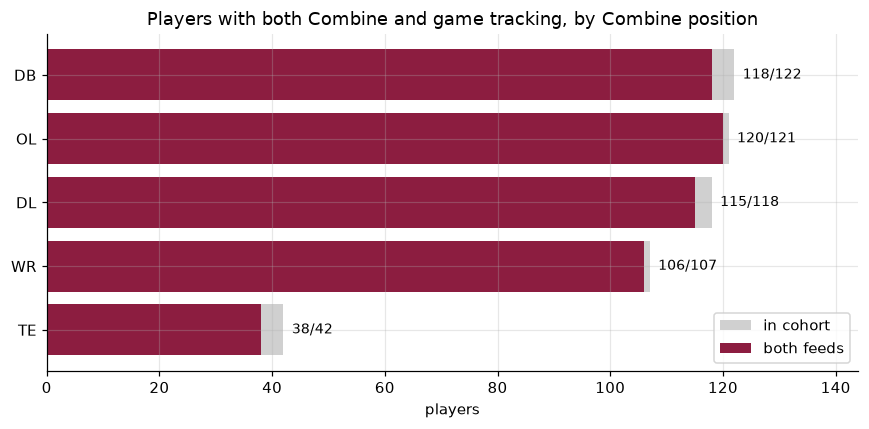

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
d = by_combine.sort_values("players")
ax.barh(d.index, d["players"], color="#d0d0d0", label="in cohort")
ax.barh(d.index, d["both"], color="#8c1d40", label="both feeds")
for i, (p, b) in enumerate(zip(d["players"], d["both"])):
    ax.text(p + 1.5, i, f"{b}/{p}", va="center", fontsize=9)
ax.set_xlabel("players")
ax.set_title("Players with both Combine and game tracking, by Combine position")
ax.legend(loc="lower right")
ax.set_xlim(0, d["players"].max() * 1.18)
fig.tight_layout()
fig.savefig(FIGURES / "overlap_by_combine_position.png", bbox_inches="tight")
plt.show()

### Overlap by season

Game tracking coverage grows each season, from 156 players in 2023 to 448 in
2025. Any idea needing multi-season game data has a much smaller usable sample
than the 497 headline figure suggests.

In [11]:
season_cols = [c for c in flags.columns if c.startswith("game_tracking_")]
per_season = pd.DataFrame({
    "players_tracked": [int(flags[c].sum()) for c in season_cols],
    "with_combine_tracking": [int((flags[c] & flags.has_combine_tracking).sum()) for c in season_cols],
}, index=[c.replace("game_tracking_", "") for c in season_cols])
per_season.index.name = "season"

n_seasons = flags[season_cols].sum(axis=1)
print("seasons of game tracking per player:")
print(n_seasons.value_counts().sort_index().rename("players").to_string())
per_season

seasons of game tracking per player:
0     13
1    195
2    179
3    123


,players_tracked,with_combine_tracking
season,,
2023,156,156
2024,318,318
2025,448,448


In [ ]:
# Draft class against how many seasons of game tracking each player has.
print(pd.crosstab(flags["draft_year"], n_seasons.rename(
    "n_seasons_tracked")).to_string())

n_seasons_tracked  0    1    2    3
draft_year                         
2023               2   12   23  123
2024               2   19  156    0
2025               9  164    0    0


## 3. Game tracking shape

One file per season, 10 Hz, with position (`x`, `y`), speed (`s`), acceleration
(`a`), distance (`dis`), orientation (`o`) and direction (`dir`). `event` is 93
percent null, populated only on frames where something happened.

In [ ]:
gt = load("game_tracking_2025")
print("rows:", f"{len(gt):,}", "| games:", gt.game_id.nunique(),
      "| plays:", gt.play_id.nunique(), "| players:", gt.nfl_id.nunique())
print("x range:", gt.x.min(), "to", gt.x.max(),
      "| y range:", gt.y.min(), "to", gt.y.max())
print("s max:", gt.s.max(), "| a max:", gt.a.max())
print("\nevent values (non-null only):")
print(gt["event"].value_counts().head(12).to_string())

rows: 11,160,903 | games: 334 | plays: 4746 | players: 448
x range: -5.86 to 127.4 | y range: -8.78 to 63.05
s max: 16.88 | a max: 33.759

event values (non-null only):


event
ball_snap                    154839
first_contact                 91278
pass_forward                  91231
tackle                        91186
pass_arrived                  68478
pass_outcome_caught           54929
handoff                       46564
pass_outcome_incomplete       31977
play_action                   25740
out_of_bounds                 16484
autoevent_passinterrupted     11209
run                            7513


In [14]:
# Frames per player-play, which sets the usable sample for any per-play metric.
fpp = gt.groupby(["game_id", "play_id", "nfl_id"]).size()
print(f"player-play combinations: {len(fpp):,}")
print(fpp.describe().round(1).to_string())

player-play combinations: 155,313
count    155313.0
mean         71.9
std          16.9
min          17.0
25%          61.0
50%          69.0
75%          80.0
max         241.0


## 4. Speed in both feeds

Combine speed and game speed are on the same nominal scale, which is what makes
the required Combine-to-game link possible. The game distribution is dominated
by low-speed frames, since most tracked frames are pre-snap or post-play.

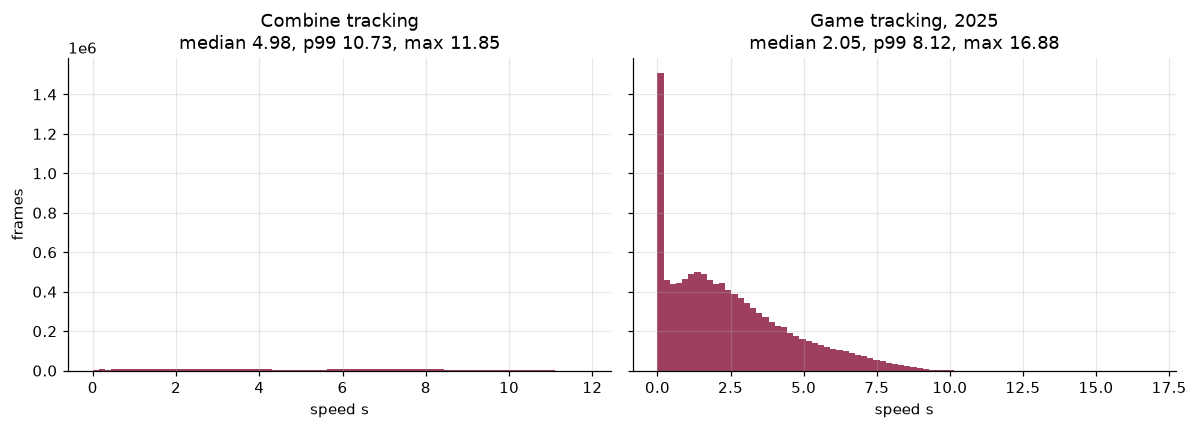

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (s, label) in zip(axes, [(ct_players["s"], "Combine tracking"),
                                 (gt["s"], "Game tracking, 2025")]):
    ax.hist(s, bins=80, color="#8c1d40", alpha=0.85)
    ax.set_title(
        f"{label}\nmedian {s.median():.2f}, p99 {s.quantile(0.99):.2f}, max {s.max():.2f}")
    ax.set_xlabel("speed s")
axes[0].set_ylabel("frames")
fig.tight_layout()
fig.savefig(FIGURES / "speed_distributions.png", bbox_inches="tight")
plt.show()

In [ ]:
# Per-player max speed in each feed, the simplest possible linked quantity.
cmax = ct_players.groupby("nfl_id")["s"].max().rename("combine_max_s")
gmax = gt.groupby("nfl_id")["s"].max().rename("game_max_s")
linked = (flags.set_index("nfl_id")[["display_name", "combine_position"]]
          .join(cmax, how="inner").join(gmax, how="inner"))
print("players with a max speed in both feeds:", len(linked))
linked.groupby("combine_position")[
    ["combine_max_s", "game_max_s"]].median().round(2)

players with a max speed in both feeds: 448


,combine_max_s,game_max_s
combine_position,,
DB,10.96,9.75
DL,9.89,7.92
OL,9.31,6.98
TE,10.45,8.62
WR,11.06,9.69


Treat that table as a plumbing check, not a finding. Combine max speed comes
from a mix of drills and game max speed from whatever snaps a player happened to
play, so the two are not measuring comparable efforts yet. Making them
comparable is idea work.

## 5. Outcome tables

`player_career_successes` gives career totals per player. `player_play` gives
per-play context and outcomes, including the columns the official examples point
at: `separation_at_pass_forward`, `route_ran`, `cushion`, `pressure_allowed`,
`player_get_off` and `coverage_assignment`.

Null rates matter here. Many of these columns are populated only for the
relevant position and play type, so effective sample sizes are far below the
314,197 rows.

In [17]:
pp = load("player_play")
cols = ["route_ran", "separation_at_pass_forward", "cushion", "expected_yards_after_catch",
        "player_get_off", "pressure_allowed", "time_to_pressure_allowed",
        "coverage_assignment", "dropback_duration", "yards_after_catch"]
avail = pd.DataFrame({
    "non_null_rows": [pp[c].notna().sum() for c in cols],
    "pct_null": [round(100 * pp[c].isna().mean(), 1) for c in cols],
    "players": [pp.loc[pp[c].notna(), "nfl_id"].nunique() for c in cols],
}, index=cols).sort_values("non_null_rows", ascending=False)
avail

,non_null_rows,pct_null,players
cushion,103752,67.0,291
coverage_assignment,72652,76.9,196
dropback_duration,60803,80.6,189
pressure_allowed,60803,80.6,189
route_ran,53308,83.0,156
separation_at_pass_forward,46737,85.1,156
player_get_off,44002,86.0,196
expected_yards_after_catch,8976,97.1,147
yards_after_catch,6260,98.0,146
time_to_pressure_allowed,4970,98.4,142


In [18]:
career = load("player_career_successes")
career.describe().round(1)

,nfl_id,career_offensive_snaps,career_defensive_snaps,career_special_teams_snaps,career_games_active,career_games_started,ap_all_pro_1st_team,ap_all_pro_2nd_team,pro_bowl_original_ballot
count,510.0,510.0,510.0,510.0,510.0,510.0,510.0,510.0,510.0
mean,57331.3,327.4,234.3,113.5,21.7,7.9,0.0,0.0,0.0
std,979.5,632.4,492.1,156.2,16.3,11.5,0.1,0.1,0.2
min,55867.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,56273.5,0.0,0.0,5.0,6.2,0.0,0.0,0.0,0.0
50%,57290.0,0.0,0.0,53.0,17.0,2.0,0.0,0.0,0.0
75%,58302.8,361.8,220.5,147.8,34.0,12.0,0.0,0.0,0.0
max,59278.0,3303.0,2666.0,957.0,51.0,50.0,1.0,1.0,2.0


## 6. Where this leaves things

Verified facts, all from the output above:

- 510 players in the cohort, across the 2023, 2024 and 2025 draft classes. All
  510 have Combine tracking.
- 497 of 510 also have game tracking. Overlap is not the limiting factor.
- Position coverage is even: five Combine groups, each between 90 and 99 percent
  complete. Smallest group is TE at 42 players, 38 with both feeds.
- Game tracking coverage by season is uneven, 156 players in 2023 against 448 in
  2025, so multi-season designs shrink the sample.
- Both feeds are 10 Hz with the same kinematic columns, confirmed from frame
  gaps rather than assumed.
- Outcome columns in `player_play` are sparse and position-conditional, so the
  real constraint is per-outcome sample size, not the player join.

Not done here, on purpose: no idea selection and no modeling.

#### Human Observation

combine results = core measurables and ngs athleticism score and college production score

tracking: contains event ids, player ids, and a distinction on whether we a tracking the player on the ball

game_tracking: player location at intervals throughout the play

